# Experiment 197 · Selective encoder adaptation

**Complete** · Experiment 197 results saved · ETA 0h 00m 00s

The decoder updates at every arrival under 50% broad-history replacement replay. When enabled, the encoder uses the full Experiment 196 learning rate. Disabled encoder steps leave weights and AdamW state unchanged. The 0% and 100% frontier endpoints reuse matching Experiment 196 trajectories. The interior periodic masks keep equal current and replay exposure among encoder-enabled arrivals. Same-process timing runs cover all four rates.

Development selection minimizes time-averaged current monitor MSE plus historical forgetting above 0.005. The better interior rate sets the equal-budget comparison. The best rate overall is the additional comparison when it uses a different budget. Scene, weather and pedestrian labels are used only for external evaluation.

The causal controller chooses an encoder-update pattern for two 256-arrival blocks. Predictions use past bank loss and RankMe trends, AdamW moment state and the measured size of a recent applied encoder update. Candidates must forecast at least 0.001 objective gain with at most 0.005 historical MSE damage. Every branch matches encoder and decoder update counts and is followed by 512 periodic arrivals.

Completed frontier runs · 48. Branch cases · 24. Full deployments · 0.

## A · Encoder-update budget frontier

| Rate | Paired runs | Unseen MSE | Historical MSE | Objective | Final RankMe | Final retrieval | Training wall time (s) | 512-arrival timing (s) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 0% | 12 | 0.88105 | 0.86336 | 0.88156 | 2.45802 | 0.55816 | 92.50 | 2.551 | 
 | 25% | 12 | 0.87480 | 0.85079 | 0.87488 | 3.28575 | 0.67448 | 106.12 | 2.912 | 
 | 50% | 12 | 0.87357 | 0.84937 | 0.87357 | 3.70769 | 0.64583 | 118.40 | 3.287 | 
 | 100% | 12 | 0.87205 | 0.84782 | 0.87207 | 4.26463 | 0.71094 | 143.20 | 3.952 | 

**Development-selected fixed rate** · 100%. **Equal-budget rate** · 50%.

## B · Held-out counterfactual gate

| Policy | Objective gain vs periodic [95% CI] | Mean oracle regret | Historical MSE gain [95% CI] |
| --- | --- | --- | --- |
 | periodic | +0.00000 [+0.00000, +0.00000] | 0.00120 | +0.00000 [+0.00000, +0.00000] | 
 | update first | +0.00004 [-0.00159, +0.00167] | 0.00116 | +0.00216 [-0.00684, +0.01116] | 
 | protect first | -0.00093 [-0.00379, +0.00193] | 0.00214 | -0.00078 [-0.00484, +0.00327] | 
 | threshold protection | -0.00017 [-0.00089, +0.00055] | 0.00137 | +0.00010 [-0.00032, +0.00051] | 
 | learned | +0.00004 [-0.00159, +0.00167] | 0.00116 | +0.00219 [-0.00694, +0.01133] | 
 | oracle | +0.00120 [-0.00100, +0.00341] | 0.00000 | +0.00038 [-0.00101, +0.00178] | 

| Prediction | Held-out objective RMSE | Development-mean RMSE |
| --- | --- | --- |
 | update first | 0.00426 | 0.00297 | 
 | protect first | 0.00527 | 0.00224 | 

**Deployment gate** · stop after branches. The learned choice needs 0.001 mean benefit and positive gain in at least two held-out seeds.

## External downstream probes

| Stage | Policy | Runs | Scene | Weather | Pedestrian |
| --- | --- | --- | --- | --- | --- |
 | A | 100% | 12 | 42.69% | 45.76% | 58.05% | 
 | A | 0% | 12 | 39.38% | 44.55% | 57.11% | 
 | A | 25% | 12 | 41.93% | 44.52% | 58.10% | 
 | A | 50% | 12 | 42.90% | 44.39% | 58.78% | 



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-encoder-budget')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


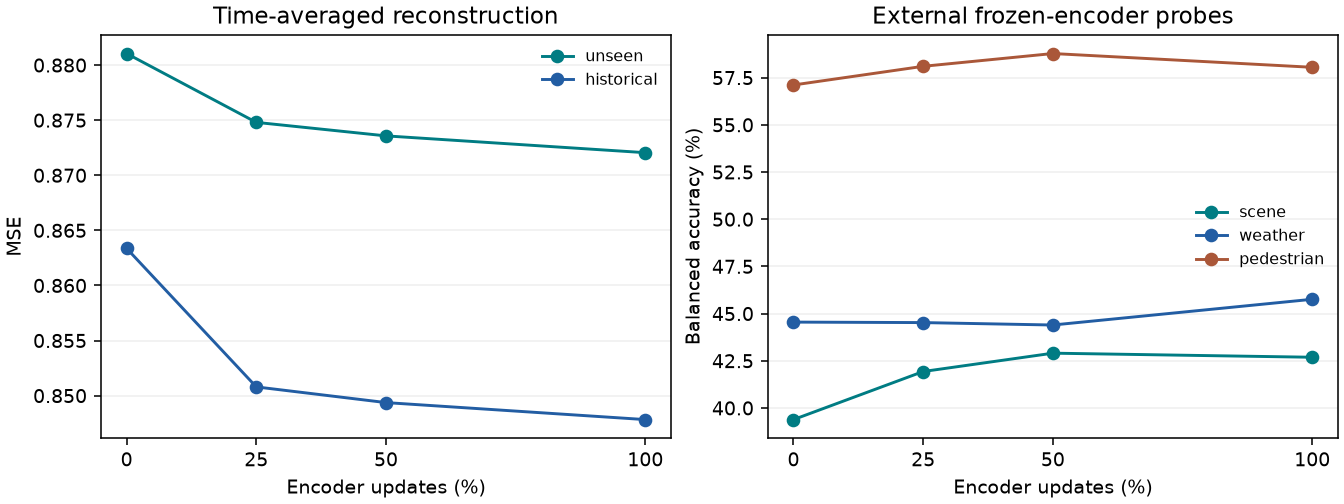